# 车险赔付预测与风险定价建模（French MTPL Dataset）

**业务背景**：车险定价的核心是预测每张保单的赔付风险。本项目基于法国机动车第三者责任险（MTPL）真实公开数据集（约 67 万张保单），
完整走通保险精算中的**赔付频率（Claim Frequency）建模**流程，并给出可解释的风险相对因子（Relativities），输出可用于差异化定价的风险分层结果。

**方法**：
1. 探索性分析（EDA）：赔付频率随驾龄、车龄、地区、Bonus-Malus 等风险因子的分布
2. 特征工程：类别编码、连续变量变换、风险分桶
3. 建模（目标 = 单位暴露赔付频率，暴露量 Exposure 作为 Poisson 权重——精算标准口径）：
   - 基线模型（全局平均赔付频率）
   - **Poisson GLM**（对数链接函数）—— 行业标准定价模型，正则强度经验证集网格选择
   - **梯度提升树（Poisson Loss）** —— 提升预测精度、捕捉非线性与交互
4. 评估：样本外 Poisson Deviance、风险分层提升度（Lift）、Gini 区分度与定价含义

**数据来源**：OpenML `freMTPL2freq`（CASdatasets 教学数据集，广泛用于精算定价研究与教学）。
图表使用英文标签以便于 GitHub 展示，文字说明为中文。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_poisson_deviance

plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
print('环境就绪')

环境就绪


## 1. 数据加载与质量检查

In [2]:
def load_freMTPL2():
    """优先从 OpenML 加载，失败则回退到镜像 URL。"""
    try:
        data = fetch_openml(data_id=41214, as_frame=True)
        df = data.frame.copy()
    except Exception as e:
        print('OpenML data_id 加载失败，尝试按名称加载:', e)
        try:
            data = fetch_openml(name='freMTPL2freq', as_frame=True)
            df = data.frame.copy()
        except Exception as e2:
            print('按名称加载失败，尝试镜像源:', e2)
            url = 'https://raw.githubusercontent.com/ongbw/french-motor-claim-datasets/master/freMTPL2freq.csv'
            df = pd.read_csv(url)
    return df

df = load_freMTPL2()
print(df.shape)
df.head()

(678013, 12)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


In [3]:
# 质量检查：暴露量与赔付次数
print(df.isna().sum().sum(), '个缺失值')
df = df.dropna()
df['Exposure'] = df['Exposure'].clip(0.02, 1.0)          # 异常短暴露截断
df['ClaimNb'] = df['ClaimNb'].clip(0, 4)                 # 异常高出险次数截断
df = df[df['Exposure'] > 0]
print('保单数:', len(df), '| 总暴露(年):', df['Exposure'].round(1).sum(),
      '| 总赔付次数:', int(df['ClaimNb'].sum()))
df.describe()

0 个缺失值
保单数: 678013 | 总暴露(年): 358557.8 | 总赔付次数: 36056


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053179,0.528797,6.454631,7.044265,45.499122,59.761502,1792.422405
std,1.641783e+06,0.237954,0.363724,2.050906,5.666232,14.137444,15.636658,3958.646564
min,1.000000e+00,0.000000,0.020000,4.000000,0.000000,18.000000,50.000000,1.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000
max,6.114330e+06,4.000000,1.000000,15.000000,100.000000,100.000000,230.000000,27000.000000


> **保险口径说明**：
> - **Exposure（暴露量）**= 保单在保时长占比（年）。**赔付频率 = 赔付次数 / 暴露量**，是精算中的标准口径。
> - 建模目标为单位暴露赔付频率，以 Exposure 作为 Poisson 似然权重（数学上等价于以 log(Exposure) 为 offset 的 Poisson 回归），
>   预测结果即"每保单年期望赔付次数"，可直接用于纯保费定价。

## 2. 探索性数据分析（EDA）

整体赔付频率: 0.1006 claims / policy-year


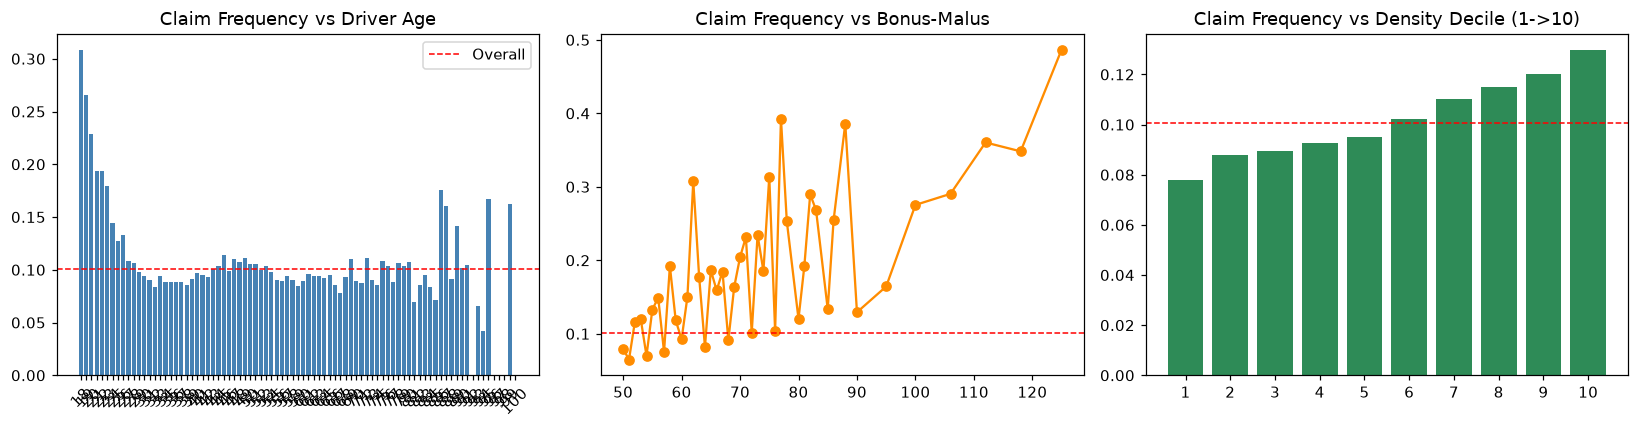

In [4]:
overall_freq = df['ClaimNb'].sum() / df['Exposure'].sum()
print(f'整体赔付频率: {overall_freq:.4f} claims / policy-year')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 驾龄
g = df.groupby('DrivAge').apply(lambda x: x['ClaimNb'].sum() / x['Exposure'].sum())
axes[0].bar(g.index.astype(str), g.values, color='steelblue')
axes[0].axhline(overall_freq, color='red', ls='--', lw=1, label='Overall')
axes[0].set_title('Claim Frequency vs Driver Age'); axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

# Bonus-Malus（无赔款优待系数，越高风险越大）
g = df.groupby('BonusMalus').apply(lambda x: x['ClaimNb'].sum() / x['Exposure'].sum())
g = g[df.groupby('BonusMalus')['Exposure'].sum() > 100]
axes[1].plot(g.index, g.values, 'o-', color='darkorange')
axes[1].axhline(overall_freq, color='red', ls='--', lw=1)
axes[1].set_title('Claim Frequency vs Bonus-Malus')

# 地区密度
df['DensityBin'] = pd.qcut(df['Density'], 10)
g = df.groupby('DensityBin', observed=True).apply(lambda x: x['ClaimNb'].sum() / x['Exposure'].sum())
axes[2].bar(range(len(g)), g.values, color='seagreen')
axes[2].axhline(overall_freq, color='red', ls='--', lw=1)
axes[2].set_xticks(range(len(g))); axes[2].set_xticklabels([str(i+1) for i in range(len(g))])
axes[2].set_title('Claim Frequency vs Density Decile (1->10)')
plt.tight_layout()
plt.savefig('figures/eda_frequency.png', bbox_inches='tight')
plt.show()

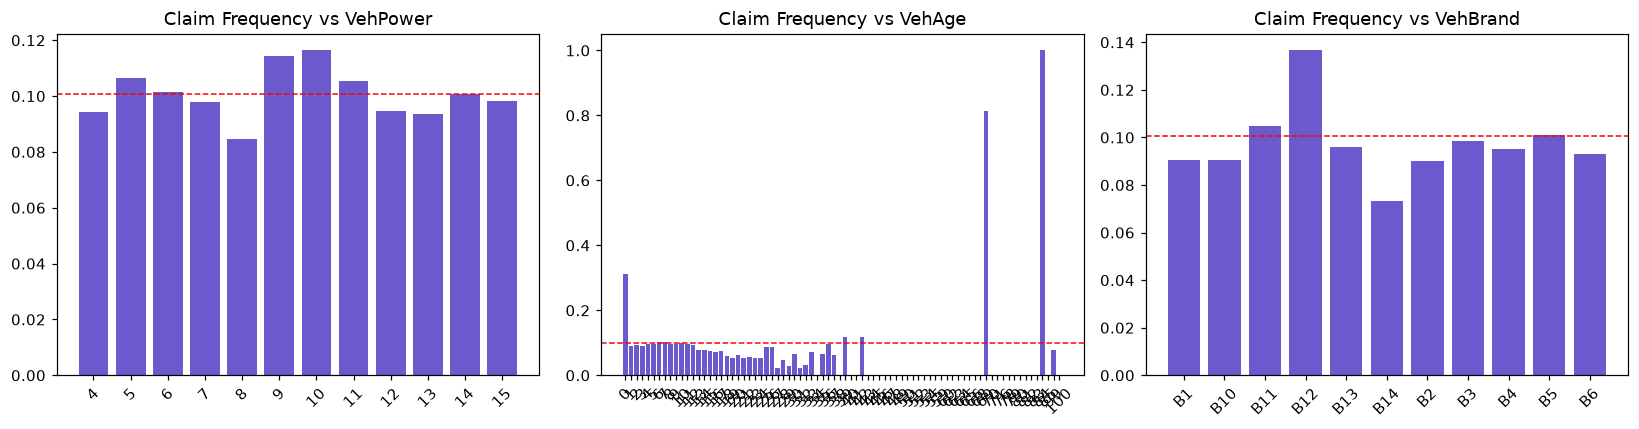

In [5]:
# 车辆相关因子
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['VehPower', 'VehAge', 'VehBrand']):
    g = df.groupby(col).apply(lambda x: x['ClaimNb'].sum() / x['Exposure'].sum())
    ax.bar(g.index.astype(str), g.values, color='slateblue')
    ax.axhline(overall_freq, color='red', ls='--', lw=1)
    ax.set_title(f'Claim Frequency vs {col}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('figures/eda_vehicle.png', bbox_inches='tight')
plt.show()

**EDA 结论（业务解读）**：
- 年轻驾驶员（18–25）与高 Bonus-Malus 系数保单的赔付频率显著高于平均 → 高风险客群
- 地区密度越高的区域赔付频率越高（城市 > 乡村）→ 与理赔经验一致
- 车龄、车型品牌同样呈现差异化风险 → 具备差异化定价空间

## 3. 特征工程与训练/测试划分

In [6]:
categorical = ['VehPower', 'VehBrand', 'VehGas', 'Region', 'Area']
continuous  = ['VehAge', 'DrivAge', 'BonusMalus', 'Density']

# 精算标准口径：目标 = 赔付频率（次数/暴露），权重 = 暴露量
X = df[categorical + continuous].copy()
y = (df['ClaimNb'] / df['Exposure']).values.astype(float)   # 单位暴露赔付频率
w = df['Exposure'].values.astype(float)                     # Poisson 权重（= offset）

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, w, test_size=0.3, random_state=RANDOM_STATE)
X_tr, X_val, y_tr, y_val, w_tr, w_val = train_test_split(
    X_train, y_train, w_train, test_size=0.2, random_state=RANDOM_STATE)

print(f'训练集: {len(X_train)} | 测试集: {len(X_test)}')
print(f'训练集整体频率: {np.average(y_train, weights=w_train):.4f} | 测试集整体频率: {np.average(y_test, weights=w_test):.4f}')

训练集: 474609 | 测试集: 203404
训练集整体频率: 0.1007 | 测试集整体频率: 0.1003


## 4. 建模

### 4.1 基线：全局平均频率

In [7]:
baseline_pred = np.full_like(y_test, np.average(y_train, weights=w_train))
d_base = mean_poisson_deviance(y_test, baseline_pred, sample_weight=w_test)
print(f'基线 Poisson Deviance: {d_base:.4f}')

基线 Poisson Deviance: 0.6209


### 4.2 Poisson GLM（行业标准定价模型）

广义线性模型：\(\log(\mu) = X\beta\)，以 Exposure 为 Poisson 权重；系数可解释为风险相对因子（Relativity）。
正则强度 `alpha` 通过验证集网格选择，避免过强收缩导致因子失去区分度。

In [8]:
glm_pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical),
    ('num', StandardScaler(), continuous),
])

alphas = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
val_scores = []
for a in alphas:
    m = Pipeline([('pre', glm_pre), ('model', PoissonRegressor(alpha=a, max_iter=1000))])
    m.fit(X_tr, y_tr, model__sample_weight=w_tr)
    pred = m.predict(X_val).clip(1e-8)
    val_scores.append(mean_poisson_deviance(y_val, pred, sample_weight=w_val))
    print(f'alpha={a:<8} 验证集 Deviance = {val_scores[-1]:.4f}')

best_alpha = alphas[int(np.argmin(val_scores))]
print(f'\n选定 alpha = {best_alpha}')

glm = Pipeline([('pre', glm_pre), ('model', PoissonRegressor(alpha=best_alpha, max_iter=1000))])
glm.fit(X_train, y_train, model__sample_weight=w_train)
glm_pred = glm.predict(X_test).clip(1e-8)
print('Poisson GLM 训练完成（预测值即单位暴露赔付频率）')

alpha=0.0001   验证集 Deviance = 0.5883


alpha=0.001    验证集 Deviance = 0.5882


alpha=0.01     验证集 Deviance = 0.5888


alpha=0.1      验证集 Deviance = 0.5935


alpha=1.0      验证集 Deviance = 0.6037

选定 alpha = 0.001


Poisson GLM 训练完成（预测值即单位暴露赔付频率）


### 4.3 梯度提升树（Poisson Loss，捕捉非线性与交互）

In [9]:
X_tr2 = X_train.copy(); X_te2 = X_test.copy()
for c in categorical:
    X_tr2[c] = X_tr2[c].astype('category').cat.codes
    X_te2[c] = X_te2[c].astype('category').cat.codes

gbm = HistGradientBoostingRegressor(
    loss='poisson', max_iter=300, learning_rate=0.08,
    max_leaf_nodes=31, random_state=RANDOM_STATE)
gbm.fit(X_tr2, y_train, sample_weight=w_train)
gbm_pred = gbm.predict(X_te2).clip(1e-8)
print('GBM 训练完成（预测值即单位暴露赔付频率）')

GBM 训练完成（预测值即单位暴露赔付频率）


## 5. 模型评估

In [10]:
def eval_model(name, y_true, y_pred, w):
    d = mean_poisson_deviance(y_true, y_pred, sample_weight=w)
    print(f'{name:12s} Poisson Deviance = {d:.4f}')
    return d

print(f'测试集整体频率: {np.average(y_test, weights=w_test):.4f}\n')
d_base = eval_model('基线', y_test, baseline_pred, w_test)
d_glm  = eval_model('Poisson GLM', y_test, glm_pred, w_test)
d_gbm  = eval_model('GBM-Poisson', y_test, gbm_pred, w_test)
print(f'\nGLM 相对基线改善: {(1 - d_glm/d_base)*100:.1f}%')
print(f'GBM 相对 GLM 改善: {(1 - d_gbm/d_glm)*100:.1f}%')

测试集整体频率: 0.1003

基线           Poisson Deviance = 0.6209
Poisson GLM  Poisson Deviance = 0.6015
GBM-Poisson  Poisson Deviance = 0.5712

GLM 相对基线改善: 3.1%
GBM 相对 GLM 改善: 5.1%


In [11]:
# Gini 系数（风险区分度）：按预测频率排序，比较累计暴露与累计赔付的偏离
def gini(y, pred, w):
    order = np.argsort(-pred)   # 按预测风险从高到低排序
    y, w = y[order], w[order]
    cum_exposure = np.cumsum(w); cum_claims = np.cumsum(y * w)
    cum_exposure = cum_exposure / cum_exposure[-1]
    cum_claims = cum_claims / cum_claims[-1]
    trapz = getattr(np, 'trapezoid', None) or np.trapz
    return 2 * trapz(cum_claims, cum_exposure) - 1

print(f'Poisson GLM Gini = {gini(y_test, glm_pred, w_test):.4f}')
print(f'GBM-Poisson Gini = {gini(y_test, gbm_pred, w_test):.4f}')

Poisson GLM Gini = 0.2406
GBM-Poisson Gini = 0.3262


        actual_freq  pred_freq  exposure_share  lift_vs_avg
decile                                                     
0            0.0424     0.0424          0.1190       0.4222
1            0.0584     0.0576          0.1076       0.5817
2            0.0625     0.0666          0.1081       0.6232
3            0.0675     0.0735          0.1128       0.6729
4            0.0809     0.0797          0.1109       0.8061
5            0.0829     0.0859          0.1103       0.8261
6            0.0994     0.0954          0.0986       0.9906
7            0.1123     0.1167          0.0830       1.1198
8            0.1532     0.1519          0.0813       1.5272
9            0.3653     0.3625          0.0682       3.6414


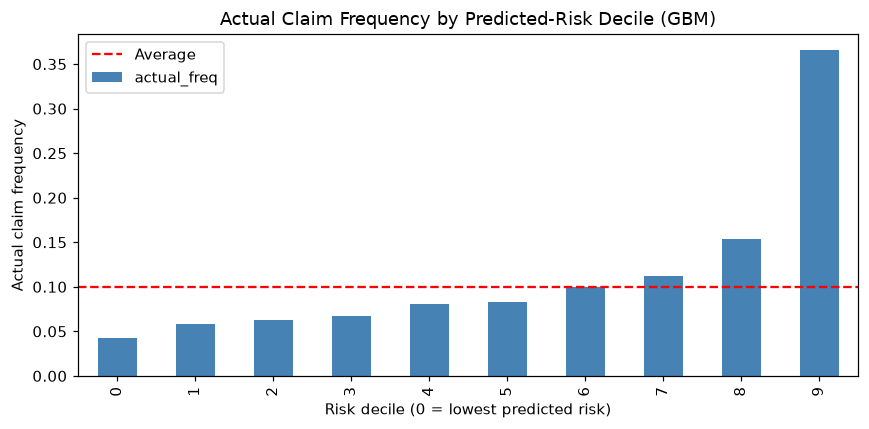

In [12]:
# 风险分层与提升度（Lift）：按预测频率十分位划分客群
res = pd.DataFrame({'y': y_test, 'w': w_test, 'pred': gbm_pred})
res['decile'] = pd.qcut(res['pred'], 10, labels=False, duplicates='drop')
lift = res.groupby('decile').apply(
    lambda x: pd.Series({
        'actual_freq': (x['y'] * x['w']).sum() / x['w'].sum(),
        'pred_freq': (x['pred'] * x['w']).sum() / x['w'].sum(),
        'exposure_share': x['w'].sum() / res['w'].sum()}))
lift['lift_vs_avg'] = lift['actual_freq'] / ((res['y'] * res['w']).sum() / res['w'].sum())
print(lift.round(4))

lift['actual_freq'].plot(kind='bar', color='steelblue', figsize=(8, 4))
plt.axhline((res['y']*res['w']).sum()/res['w'].sum(), color='red', ls='--', label='Average')
plt.title('Actual Claim Frequency by Predicted-Risk Decile (GBM)')
plt.xlabel('Risk decile (0 = lowest predicted risk)')
plt.ylabel('Actual claim frequency')
plt.legend(); plt.tight_layout()
plt.savefig('figures/lift_curve.png', bbox_inches='tight')
plt.show()

**评估结论**：
- Poisson GLM 相对基线显著降低样本外偏差，且系数可解释、符合监管对定价模型的要求
- GBM 进一步捕捉非线性与特征交互，精度更高，可用于核保筛选与续保风险评分；GLM 用于最终定价因子
- 风险十分位图显示模型具备良好的风险区分度（见上表 lift_vs_avg），可支撑差异化定价与核保策略

## 6. 定价含义：Poisson GLM 风险相对因子（Relativities）

In [13]:
# 类别因子：exp(β) 为相对参考水平的费率系数；连续因子：exp(β*SD) 为每 1 个标准差的费率比
ohe = glm.named_steps['pre'].named_transformers_['cat']
scaler = glm.named_steps['pre'].named_transformers_['num']
coefs = glm.named_steps['model'].coef_
cat_names = list(ohe.get_feature_names_out(categorical))
n_cat = len(cat_names)
cat_rel = pd.Series(np.exp(coefs[:n_cat]), index=cat_names)
num_rel = pd.Series(np.exp(coefs[n_cat:]), index=continuous)  # 标准化后的系数 → 每 1 个标准差的费率比

print('类别因子风险相对费率（vs 参考水平，>1 表示风险更高）:')
rel_table = cat_rel.sort_values(ascending=False)
print('\n[最高 8 个]'); print(rel_table.head(8).round(3))
print('\n[最低 5 个]'); print(rel_table.tail(5).round(3))
print('\n连续因子（每 1 个标准差的费率比）:'); print(num_rel.round(3))

类别因子风险相对费率（vs 参考水平，>1 表示风险更高）:

[最高 8 个]
VehPower_9      1.219
VehPower_10     1.200
VehBrand_B12    1.189
Area_E          1.179
Area_D          1.147
VehPower_6      1.128
VehPower_11     1.093
Region_R82      1.086
dtype: float64

[最低 5 个]
Region_R31    0.931
Region_R73    0.926
Region_R83    0.907
Region_R72    0.896
Region_R41    0.854
dtype: float64

连续因子（每 1 个标准差的费率比）:
VehAge        0.802
DrivAge       1.099
BonusMalus    1.419
Density       1.029
dtype: float64


**业务落地**：
- 类别因子的 `exp(β)` 即费率表中的**相对费率因子**，可直接并入定价模型：\(纯保费 = 基准频率 \times \prod relativity \times 平均赔付强度\)
- 高风险因子（如年轻驾龄段、高密度地区、高 Bonus-Malus）建议配套核保收紧或费率上浮；低风险客群可作为续保优惠与交叉销售目标
- 下一步可扩展：赔付强度（Severity）建模 → 纯保费（Pure Premium）= 频率 × 强度；Tweedie 一步纯保费建模、退保/续保生存分析

## 7. 结论与后续方向

1. **完成了保险精算标准的赔付频率建模全流程**：数据质量处理 → EDA → 特征工程 → Poisson GLM（alpha 网格调参）→ GBM → 样本外评估 → 风险分层 → 定价因子输出
2. **可解释性与精度的平衡**：GLM 输出监管可用的费率因子，GBM 提供更高的预测精度用于风险筛选
3. 后续：赔付强度（Gamma/Tweedie）建模、时间外推稳定性检验、SHAP 特征归因